# Ensemble Learning on Sri Lankan Weather Data

**Student:** 224053R

**Module:** Machine Learning and Pattern Recognition

## Project overview
This notebook compares ensemble learning methods (Bagging, Boosting, Stacking and a Hybrid model) on a local Sri Lankan weather dataset. The dataset contains daily weather records for 30 Sri Lankan cities from 2010 to 2023.

## Objective
Predict tomorrow's maximum temperature in **Colombo** from today's weather conditions and recent history. This is a regression problem, so model performance is measured with MAE, RMSE and R².

In [1]:
!pip install pandas numpy scikit-learn xgboost lightgbm catboost statsmodels imbalanced-learn joblib matplotlib seaborn

   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
    --------------------------------------- 0.3/10.8 MB ? eta -:--:--
   -- ------------------------------------- 0.8/10.8 MB 2.2 MB/s eta 0:00:05
   --- ------------------------------------ 1.0/10.8 MB 2.2 MB/s eta 0:00:05
   ----- ---------------------------------- 1.6/10.8 MB 2.2 MB/s eta 0:00:05
   ------- -------------------------------- 2.1/10.8 MB 2.1 MB/s eta 0:00:05
   -------- ------------------------------- 2.4/10.8 MB 2.2 MB/s eta 0:00:04
   ---------- ----------------------------- 2.9/10.8 MB 2.2 MB/s eta 0:00:04
   ------------ --------------------------- 3.4/10.8 MB 2.2 MB/s eta 0:00:04
   -------------- ------------------------- 3.9/10.8 MB 2.2 MB/s eta 0:00:04
   ---------------- ----------------------- 4.5/10.8 MB 2.2 MB/s eta 0:00:03
   ----------------- ---------------------- 4.7/10.8 MB 2.1 MB/s eta 0:00:03
   ------------------ --------------------- 5.0/10.8 MB 2.1 MB/s eta 0:00:03
   ----------

In [1]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__, "| numpy:", np.__version__, "| scikit-learn:", sklearn.__version__)

Python: 3.12.10
pandas: 3.1.1 | numpy: 2.5.5 | scikit-learn: 1.9.1


In [2]:
DATA_PATH = "SriLanka_Weather_Dataset.csv"  

raw = pd.read_csv(DATA_PATH, parse_dates=["time"])
print("Shape (rows, columns):", raw.shape)
raw.head()

Shape (rows, columns): (147480, 24)


,time,weathercode,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,apparent_temperature_mean,sunrise,sunset,shortwave_radiation_sum,precipitation_sum,rain_sum,snowfall_sum,precipitation_hours,windspeed_10m_max,windgusts_10m_max,winddirection_10m_dominant,et0_fao_evapotranspiration,latitude,longitude,elevation,country,city
0,2010-01-01,2,30.0,22.7,26.1,34.4,25.2,29.2,2010-01-01T00:52,2010-01-01T12:35,20.92,0.0,0.0,0.0,0.0,11.7,27.4,20,4.58,7.0,79.899994,16.0,Sri Lanka,Colombo
1,2010-01-02,51,29.9,23.5,26.2,33.8,26.2,29.8,2010-01-02T00:52,2010-01-02T12:36,17.71,0.1,0.1,0.0,1.0,13.0,27.0,24,3.84,7.0,79.899994,16.0,Sri Lanka,Colombo
2,2010-01-03,51,29.5,23.2,26.0,34.3,26.3,29.9,2010-01-03T00:53,2010-01-03T12:36,17.76,0.6,0.6,0.0,3.0,12.3,27.4,16,3.65,7.0,79.899994,16.0,Sri Lanka,Colombo
3,2010-01-04,2,28.9,21.9,25.3,31.6,23.4,27.8,2010-01-04T00:53,2010-01-04T12:37,16.50,0.0,0.0,0.0,0.0,17.0,34.6,356,3.79,7.0,79.899994,16.0,Sri Lanka,Colombo
4,2010-01-05,1,28.1,21.3,24.5,30.1,23.1,26.1,2010-01-05T00:53,2010-01-05T12:37,23.61,0.0,0.0,0.0,0.0,18.7,37.1,355,4.97,7.0,79.899994,16.0,Sri Lanka,Colombo


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 147480 entries, 0 to 147479
Data columns (total 24 columns):
 #   Column                      Non-Null Count   Dtype         
---  ------                      --------------   -----         
 0   time                        147480 non-null  datetime64[us]
 1   weathercode                 147480 non-null  int64         
 2   temperature_2m_max          147480 non-null  float64       
 3   temperature_2m_min          147480 non-null  float64       
 4   temperature_2m_mean         147480 non-null  float64       
 5   apparent_temperature_max    147480 non-null  float64       
 6   apparent_temperature_min    147480 non-null  float64       
 7   apparent_temperature_mean   147480 non-null  float64       
 8   sunrise                     147480 non-null  str           
 9   sunset                      147480 non-null  str           
 10  shortwave_radiation_sum     147480 non-null  float64       
 11  precipitation_sum           147480 non-null  float

In [4]:
missing = raw.isna().sum()
print("Total missing values:", int(missing.sum()))
missing[missing > 0]

Total missing values: 0


Series([], dtype: int64)

In [5]:
print("Date range:", raw["time"].min().date(), "to", raw["time"].max().date())
print("Number of cities:", raw["city"].nunique())
raw["city"].value_counts().head(10)

Date range: 2010-01-01 to 2023-06-17
Number of cities: 30


city
Colombo                      4916
Mount Lavinia                4916
Kesbewa                      4916
Moratuwa                     4916
Maharagama                   4916
Ratnapura                    4916
Kandy                        4916
Negombo                      4916
Sri Jayewardenepura Kotte    4916
Kalmunai                     4916
Name: count, dtype: int64

In [6]:
constant_cols = [c for c in raw.columns if raw[c].nunique(dropna=True) <= 1]
print("Columns with a single unique value:", constant_cols)

Columns with a single unique value: ['snowfall_sum', 'country']


## Subset to Colombo and exploratory analysis
The ensemble models and the ARIMA hybrid are compared on a single city's daily series, so every model sees the same data. Here we keep Colombo, check that the daily series has no gaps or duplicate dates, and look at how temperature and rainfall behave over time.

In [7]:
CITY = "Colombo"

df = (raw[raw["city"] == CITY]
      .drop(columns=["country", "city", "snowfall_sum"])
      .sort_values("time")
      .reset_index(drop=True))

print("Rows for", CITY, ":", len(df))
df.head(3)

Rows for Colombo : 4916


,time,weathercode,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,apparent_temperature_mean,sunrise,sunset,shortwave_radiation_sum,precipitation_sum,rain_sum,precipitation_hours,windspeed_10m_max,windgusts_10m_max,winddirection_10m_dominant,et0_fao_evapotranspiration,latitude,longitude,elevation
0,2010-01-01,2,30.0,22.7,26.1,34.4,25.2,29.2,2010-01-01T00:52,2010-01-01T12:35,20.92,0.0,0.0,0.0,11.7,27.4,20,4.58,7.0,79.899994,16.0
1,2010-01-02,51,29.9,23.5,26.2,33.8,26.2,29.8,2010-01-02T00:52,2010-01-02T12:36,17.71,0.1,0.1,1.0,13.0,27.0,24,3.84,7.0,79.899994,16.0
2,2010-01-03,51,29.5,23.2,26.0,34.3,26.3,29.9,2010-01-03T00:53,2010-01-03T12:36,17.76,0.6,0.6,3.0,12.3,27.4,16,3.65,7.0,79.899994,16.0


In [8]:
full_range = pd.date_range(df["time"].min(), df["time"].max(), freq="D")

print("Expected daily records:", len(full_range))
print("Actual records:        ", len(df))
print("Duplicate dates:       ", int(df["time"].duplicated().sum()))
print("Missing dates:         ", len(full_range.difference(df["time"])))

Expected daily records: 4916
Actual records:         4916
Duplicate dates:        0
Missing dates:          0


In [9]:
same_values = np.allclose(df["rain_sum"], df["precipitation_sum"])
print("rain_sum identical to precipitation_sum:", same_values)

rain_sum identical to precipitation_sum: True


In [10]:
key_cols = ["temperature_2m_max", "temperature_2m_min", "precipitation_sum",
            "windspeed_10m_max", "shortwave_radiation_sum", "et0_fao_evapotranspiration"]
df[key_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
temperature_2m_max,4916.0,29.71,1.62,22.00,28.70,29.40,30.50,36.10
temperature_2m_min,4916.0,24.43,1.08,18.90,23.90,24.50,25.20,27.10
precipitation_sum,4916.0,7.18,10.34,0.00,1.10,3.80,9.60,198.70
windspeed_10m_max,4916.0,14.32,4.30,4.50,11.00,14.20,17.40,39.40
shortwave_radiation_sum,4916.0,17.81,4.02,1.76,15.61,18.37,20.73,26.51
et0_fao_evapotranspiration,4916.0,3.68,0.89,0.64,3.14,3.71,4.27,6.24


### Temperature and rainfall over time
These plots show the long-term pattern, seasonality and day-to-day variation. Rainfall is shown as daily totals.

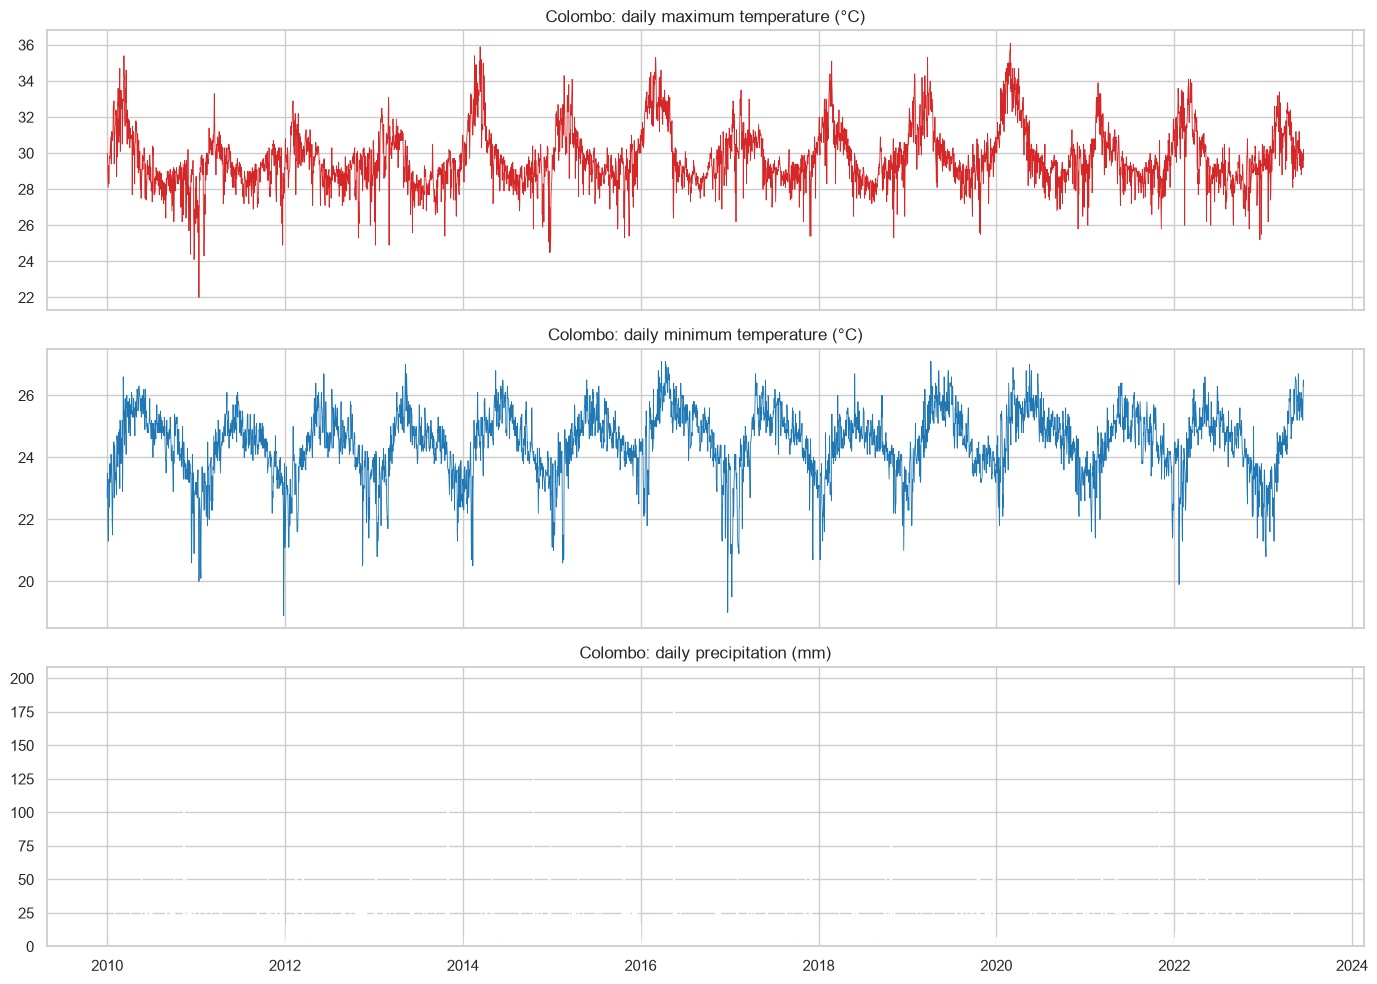

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(df["time"], df["temperature_2m_max"], lw=0.6, color="tab:red")
axes[0].set_title(f"{CITY}: daily maximum temperature (°C)")

axes[1].plot(df["time"], df["temperature_2m_min"], lw=0.6, color="tab:blue")
axes[1].set_title(f"{CITY}: daily minimum temperature (°C)")

axes[2].bar(df["time"], df["precipitation_sum"], width=1.0, color="tab:cyan")
axes[2].set_title(f"{CITY}: daily precipitation (mm)")

plt.tight_layout()
plt.show()

### Seasonal pattern and yearly trend
The monthly averages show the seasonal cycle, which the model will need to capture. The yearly averages show whether there is a warming or drying trend across 2010–2023.

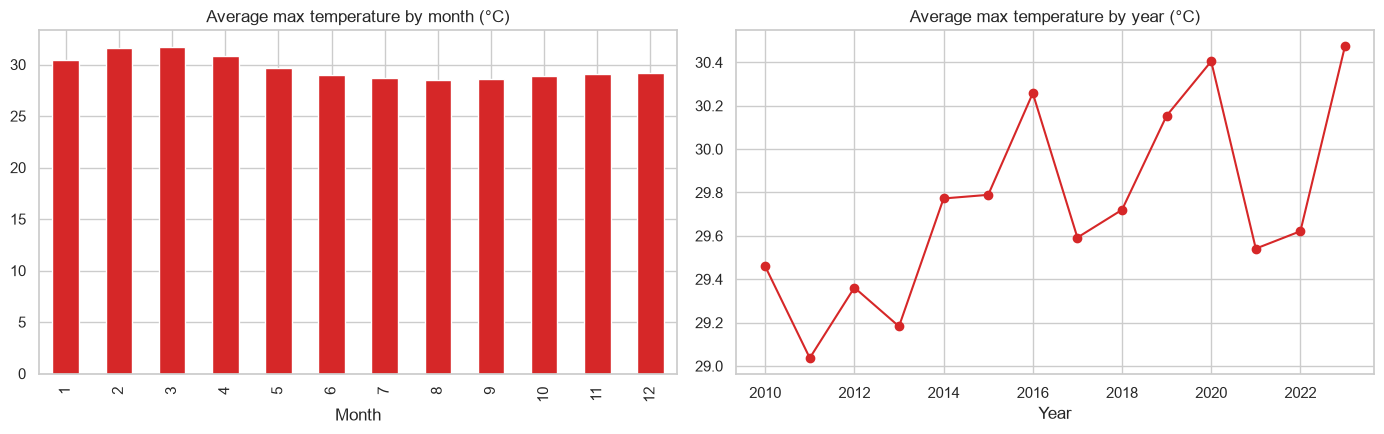

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

monthly = df.groupby(df["time"].dt.month)[["temperature_2m_max", "precipitation_sum"]].mean()
monthly["temperature_2m_max"].plot(kind="bar", ax=axes[0], color="tab:red")
axes[0].set_title("Average max temperature by month (°C)")
axes[0].set_xlabel("Month")

yearly = df.groupby(df["time"].dt.year)[["temperature_2m_max", "precipitation_sum"]].mean()
yearly["temperature_2m_max"].plot(marker="o", ax=axes[1], color="tab:red")
axes[1].set_title("Average max temperature by year (°C)")
axes[1].set_xlabel("Year")

plt.tight_layout()
plt.show()

### Correlation between variables
The heatmap shows how the same-day weather variables relate to each other. Strong correlations between features suggest redundancy, which we'll consider when selecting features in Step 3.

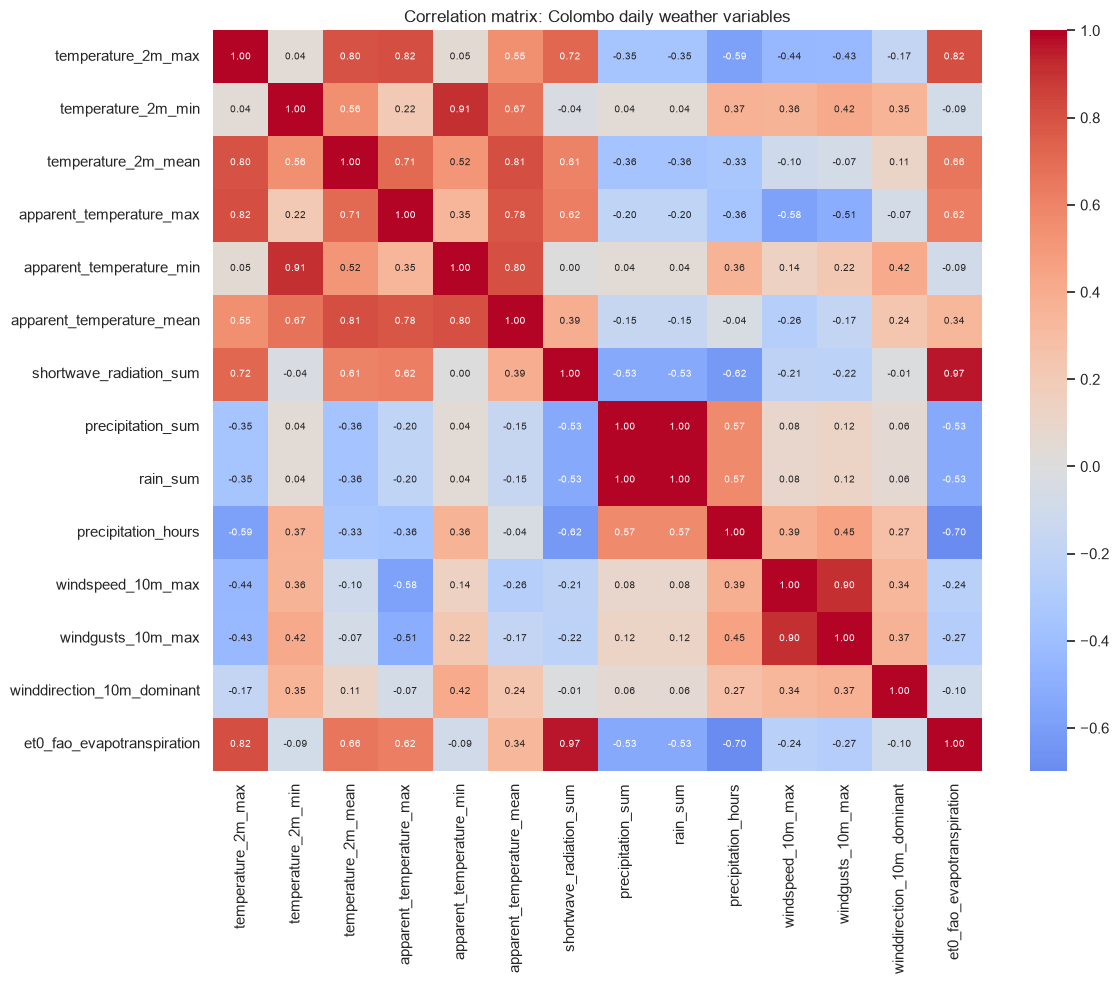

In [13]:
num_cols = df.select_dtypes("number").drop(columns=["latitude", "longitude", "elevation", "weathercode"])
corr = num_cols.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title(f"Correlation matrix: {CITY} daily weather variables")
plt.tight_layout()
plt.show()

### Findings from exploratory analysis
- **Completeness:** 4,916 daily records for Colombo, covering 2010-01-01 to 2023-06-17, with no missing or duplicate dates. The series is continuous, so lag features and ARIMA can be applied directly.
- **Duplicate column:** `rain_sum` is identical to `precipitation_sum`, so `rain_sum` is dropped and `precipitation_sum` is kept.
- **Seasonality:** the hottest months are February to April (about 30.4 to 31.7 °C on average), and the coolest are June to September (about 28.4 to 28.9 °C). This seasonal cycle is strong and should be captured by the features.
- **Trend:** the yearly average maximum temperature rises from about 29.0 °C (2011) to about 30.5 °C (2023), with year-to-year variation. The 2023 value covers only January to June and is not a full-year figure.
- **Rainfall:** the distribution is heavily skewed (median 3.8 mm, maximum 198.7 mm), with many light-rain days and a few very wet days.
- **Correlations:** `temperature_2m_max` correlates most strongly with `et0_fao_evapotranspiration` (0.82), `apparent_temperature_max` (0.82) and `temperature_2m_mean` (0.80). It correlates weakly with precipitation (−0.35).
- **Redundant features:** `shortwave_radiation_sum` and `et0_fao_evapotranspiration` (0.97), `windspeed_10m_max` and `windgusts_10m_max` (0.90), and the apparent temperature columns, which mirror the actual temperature columns. One feature from each pair will be kept.
- **Implication:** features will be built from today's values, lagged temperatures (1, 2, 3 and 7 days), a 7-day precipitation mean and seasonal encoding. Target is tomorrow's maximum temperature.

## Target, features and train/test split

###  Define the target
The target is the maximum temperature on the following day. Each row contains today's weather, and the target on that row is tomorrow's maximum temperature.

In [14]:
df["target"] = df["temperature_2m_max"].shift(-1)  # tomorrow's max temperature

In [15]:
for lag in [1, 2, 3, 7]:
    df[f"tmax_lag{lag}"] = df["temperature_2m_max"].shift(lag)

df["precip_7d_mean"] = df["precipitation_sum"].rolling(7).mean()

doy = df["time"].dt.dayofyear
df["doy_sin"] = np.sin(2 * np.pi * doy / 365.25)
df["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

### Select the feature list
The feature list reflects the Step 2 findings:
- `rain_sum` is removed because it duplicates `precipitation_sum`.
- The apparent temperature columns are removed because they mirror the actual temperature columns.
- `windspeed_10m_max` is kept, and `windgusts_10m_max` is removed because the two are nearly identical (0.90).
- `et0_fao_evapotranspiration` is kept, and `shortwave_radiation_sum` is removed because the two are nearly identical (0.97), and `et0` correlates more strongly with the target (0.82 vs 0.72).
- Sunrise, sunset, country, city, latitude, longitude, elevation and weathercode are not used. The first two are text-based, the next four are constant for a single city, and `weathercode` is a category that would need encoding.

`tmax_today` is today's maximum temperature (the same column as `temperature_2m_max`). It's included because it's known on the day of prediction.

In [16]:
df["tmax_today"] = df["temperature_2m_max"]

FEATURES = [
    "tmax_today", "tmax_lag1", "tmax_lag2", "tmax_lag3", "tmax_lag7",
    "temperature_2m_min", "temperature_2m_mean",
    "precipitation_sum", "precipitation_hours", "precip_7d_mean",
    "windspeed_10m_max", "winddirection_10m_dominant",
    "et0_fao_evapotranspiration",
    "doy_sin", "doy_cos",
]
TARGET = "target"

model_df = df.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print("Feature count:", len(FEATURES))
print("Usable rows after lags and target shift:", len(model_df))

Feature count: 15
Usable rows after lags and target shift: 4908


In [17]:
SPLIT_DATE = "2022-01-01"

train = model_df[model_df["time"] < SPLIT_DATE]
test = model_df[model_df["time"] >= SPLIT_DATE]

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print("Train:", len(train), "rows,", train["time"].min().date(), "to", train["time"].max().date())
print("Test: ", len(test), "rows,", test["time"].min().date(), "to", test["time"].max().date())
print("Missing values in features:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))
print("Mean target, train:", round(y_train.mean(), 2), "| test:", round(y_test.mean(), 2))

Train: 4376 rows, 2010-01-08 to 2021-12-31
Test:  532 rows, 2022-01-01 to 2023-06-16
Missing values in features: 0
Mean target, train: 29.69 | test: 29.89


In [18]:
check = df.set_index("time")
assert check.loc["2010-01-02", "target"] == check.loc["2010-01-03", "temperature_2m_max"], "Target is not tomorrow's value"
print("Target alignment check passed.")

Target alignment check passed.


In [19]:
series = df.set_index("time")["temperature_2m_max"]
series_train = series[series.index < SPLIT_DATE]
series_test = series[series.index >= SPLIT_DATE]
print("ARIMA train series:", len(series_train), "days | test series:", len(series_test), "days")

ARIMA train series: 4383 days | test series: 533 days


- **Target:** tomorrow's maximum temperature in Colombo.
- **Features:** 15 features covering today's weather, lagged maximum temperatures (1, 2, 3 and 7 days earlier), a 7-day precipitation mean, and seasonal encoding.
- **Split:** 4,376 training rows (2010-01-08 to 2021-12-31) and 532 test rows (2022-01-01 to 2023-06-16). The first 7 days are lost to the lags, and the last day has no target.
- **Checks:** no missing values in the features. The target alignment check passed, confirming each target is the following day's maximum.
- **Distribution shift:** the mean target is 29.69 °C in training and 29.89 °C in testing, so the test period is slightly warmer. This may affect model accuracy and should be discussed in the interpretation.
- **ARIMA series:** 4,383 training days and 533 test days, which includes the day before the first test target as history.

## Bagging (Random Forest) and Boosting (XGBoost)
Two tree-based ensembles are compared on the same features and split. Random Forest (bagging) builds many trees in parallel on random samples and averages them. XGBoost (boosting) builds trees one after another, with each tree correcting the errors of the previous ones. Both are tuned with `GridSearchCV` using `TimeSeriesSplit`, so the validation folds always come after their training data.

In [20]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

tscv = TimeSeriesSplit(n_splits=5)

def evaluate(name, y_true, y_pred):
    return {
        "model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

In [21]:
rf_grid = {
    "n_estimators": [200, 400],
    "max_depth": [6, 10, None],
    "min_samples_leaf": [2, 5],
}
rf_search = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    rf_grid, cv=tscv, scoring="neg_root_mean_squared_error",
)
rf_search.fit(X_train, y_train)
rf_best = rf_search.best_estimator_

print("Best RF parameters:", rf_search.best_params_)
print("Best validation RMSE:", round(-rf_search.best_score_, 3))

Best RF parameters: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}
Best validation RMSE: 0.794


In [22]:
xgb_grid = {
    "n_estimators": [300, 600],
    "max_depth": [3, 5],
    "learning_rate": [0.03, 0.1],
    "subsample": [0.8],
}
xgb_search = GridSearchCV(
    XGBRegressor(random_state=42, objective="reg:squarederror"),
    xgb_grid, cv=tscv, scoring="neg_root_mean_squared_error",
)
xgb_search.fit(X_train, y_train)
xgb_best = xgb_search.best_estimator_

print("Best XGBoost parameters:", xgb_search.best_params_)
print("Best validation RMSE:", round(-xgb_search.best_score_, 3))

Best XGBoost parameters: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}
Best validation RMSE: 0.792


In [23]:
rf_pred = rf_best.predict(X_test)
xgb_pred = xgb_best.predict(X_test)
naive_pred = X_test["tmax_today"].values  # tomorrow = today

results_step4 = pd.DataFrame([
    evaluate("Random Forest", y_test, rf_pred),
    evaluate("XGBoost", y_test, xgb_pred),
    evaluate("Naive (tomorrow = today)", y_test, naive_pred),
]).round(3)
results_step4

,model,MAE,RMSE,R2
0,Random Forest,0.627,0.862,0.706
1,XGBoost,0.623,0.842,0.720
2,Naive (tomorrow = today),0.714,1.006,0.600


In [24]:
preds = pd.DataFrame({
    "target_date": test["time"].values + np.timedelta64(1, "D"),
    "actual": y_test.values,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
    "Naive": naive_pred,
})
preds.head()

,target_date,actual,Random Forest,XGBoost,Naive
0,2022-01-02,31.3,31.055677,31.080017,31.1
1,2022-01-03,30.3,30.928038,30.989847,31.3
2,2022-01-04,30.3,30.039413,30.161600,30.3
3,2022-01-05,29.8,30.369476,30.140661,30.3
4,2022-01-06,31.9,30.171570,29.967995,29.8


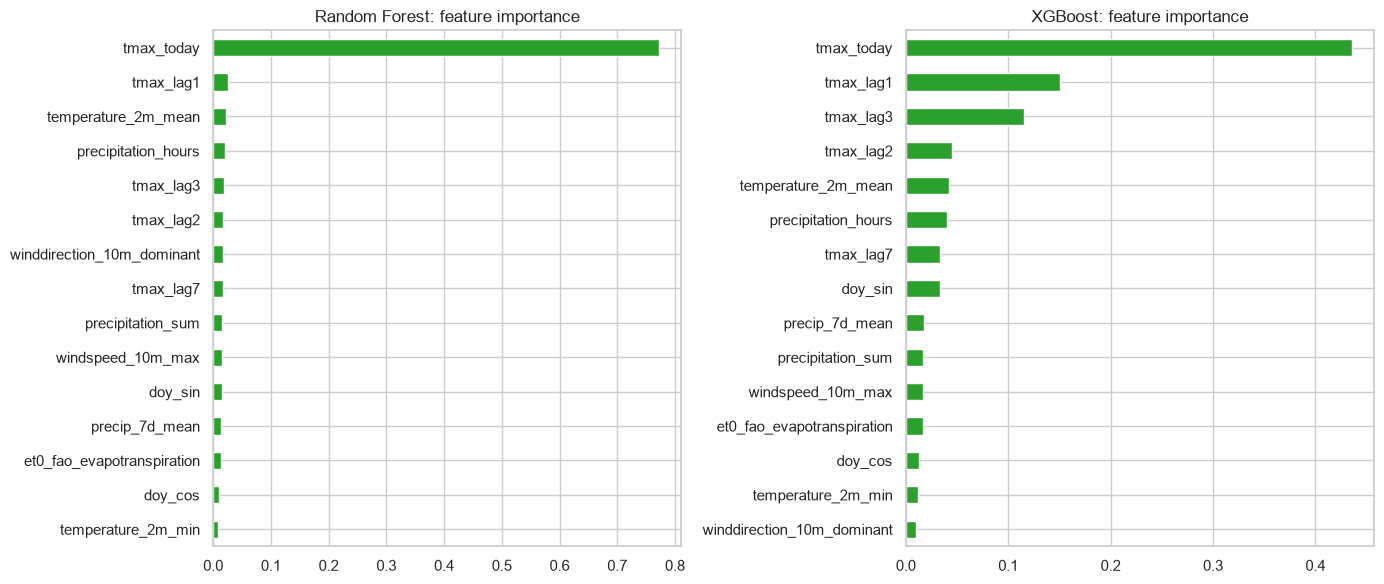

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (name, model) in zip(axes, [("Random Forest", rf_best), ("XGBoost", xgb_best)]):
    imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
    imp.plot(kind="barh", ax=ax, color="tab:green")
    ax.set_title(f"{name}: feature importance")
plt.tight_layout()
plt.show()

### Findings
- **Best parameters:** Random Forest used 200 trees, unlimited depth and a minimum of 5 samples per leaf. XGBoost used 300 rounds, depth 3, learning rate 0.03 and subsample 0.8. Validation RMSE was 0.794 for Random Forest and 0.792 for XGBoost.
- **Test results:** both models outperform the naive baseline. Random Forest reduces RMSE from 1.006 to 0.862 (about 14%), and XGBoost reduces it to 0.842 (about 16%).
- **Which model did better:** XGBoost is slightly better on all three test metrics, but the margin is small and the validation results are nearly tied. One test period isn't enough to call a clear winner.
- **Top features:** today's maximum temperature dominates both models. XGBoost also uses lagged temperatures (1 and 3 days earlier), while Random Forest relies almost entirely on today's value. Both models rank rainfall and seasonality low, so the models mostly learn persistence with small corrections.
- **Limitation:** XGBoost's best settings sit at the edge of its grid, so a wider search might improve it.

## Stacking (Random Forest + ARIMA)
Stacking trains two base models independently: Random Forest on the weather features, and ARIMA on the temperature series alone. A Ridge meta-learner then learns how much weight to give each model's prediction.

To keep the meta-learner honest, it is trained only on out-of-fold predictions. Each prediction is made by a model that did not see that day during fitting. ARIMA's order is selected by AIC on the training series, and its forecasts are one-step-ahead, updated with actual observations, the same way as the test period.

In [26]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.base import clone
from sklearn.linear_model import Ridge

best_aic, best_order = np.inf, None
for p in range(4):
    for d in range(2):
        for q in range(3):
            try:
                res = ARIMA(series_train.values, order=(p, d, q)).fit()
                if res.aic < best_aic:
                    best_aic, best_order = res.aic, (p, d, q)
            except Exception:
                continue

print("Best ARIMA order:", best_order, "| AIC:", round(best_aic, 1))

C:\Users\ASUS\.pyenv\pyenv-win\versions\3.12.10\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
C:\Users\ASUS\.pyenv\pyenv-win\versions\3.12.10\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\ASUS\.pyenv\pyenv-win\versions\3.12.10\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Best ARIMA order: (2, 0, 2) | AIC: 10777.4


In [33]:
res_best = ARIMA(series_train.values, order=best_order).fit()

print("Converged:", res_best.mle_retvals.get("converged"))
print("AR roots (should all be > 1 in absolute value):", np.round(np.abs(res_best.arroots), 3))
print("MA roots (should all be > 1 in absolute value):", np.round(np.abs(res_best.maroots), 3))
print(res_best.summary().tables[1])

Converged: True
AR roots (should all be > 1 in absolute value): [1.012 1.765]
MA roots (should all be > 1 in absolute value): [1.157 5.555]
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         29.7041      0.300     98.910      0.000      29.116      30.293
ar.L1          1.5546      0.045     34.338      0.000       1.466       1.643
ar.L2         -0.5598      0.044    -12.607      0.000      -0.647      -0.473
ma.L1         -1.0443      0.047    -22.274      0.000      -1.136      -0.952
ma.L2          0.1556      0.032      4.936      0.000       0.094       0.217
sigma2         0.6824      0.010     71.529      0.000       0.664       0.701


In [27]:
pos_of = pd.Series(np.arange(len(series)), index=series.index)
model_df["target_pos"] = model_df["time"].map(pos_of) + 1

train_rows = model_df[model_df["time"] < SPLIT_DATE].reset_index(drop=True)
test_rows = model_df[model_df["time"] >= SPLIT_DATE].reset_index(drop=True)

print("Training rows:", len(train_rows), "| test rows:", len(test_rows))

Training rows: 4376 | test rows: 532


In [28]:
def rf_out_of_fold(rows):
    oof = np.full(len(rows), np.nan)
    for tr_idx, va_idx in tscv.split(rows):
        m = clone(rf_best).fit(rows[FEATURES].iloc[tr_idx], rows[TARGET].iloc[tr_idx])
        oof[va_idx] = m.predict(rows[FEATURES].iloc[va_idx])
    return oof

def arima_out_of_fold(rows, order):
    oof = np.full(len(rows), np.nan)
    tgt = rows["target_pos"].values
    for tr_idx, va_idx in tscv.split(rows):
        fit_end = tgt[tr_idx].max()
        res = ARIMA(series.values[:fit_end + 1], order=order).fit()
        first, last = tgt[va_idx].min(), tgt[va_idx].max()
        filt = ARIMA(series.values[:last + 1], order=order).filter(res.params)
        block = filt.predict(start=first, end=last)  # one-step-ahead forecasts
        oof[va_idx] = block[tgt[va_idx] - first]
    return oof

oof_rf = rf_out_of_fold(train_rows)
oof_arima = arima_out_of_fold(train_rows, best_order)

In [29]:
valid = ~np.isnan(oof_rf) & ~np.isnan(oof_arima)
meta_X = np.column_stack([oof_rf[valid], oof_arima[valid]])
meta_y = train_rows[TARGET].values[valid]

meta = Ridge(alpha=1.0).fit(meta_X, meta_y)
print("Rows used to train meta-learner:", int(valid.sum()))
print("Weights [RF, ARIMA]:", np.round(meta.coef_, 3), "| intercept:", round(meta.intercept_, 3))

Rows used to train meta-learner: 3645
Weights [RF, ARIMA]: [0.698 0.322] | intercept: -0.546


In [30]:
rf_test = rf_best.predict(X_test)

train_end = pos_of[pd.Timestamp(SPLIT_DATE) - pd.Timedelta(days=1)]
res_full = ARIMA(series.values[:train_end + 1], order=best_order).fit()

first_t = test_rows["target_pos"].min()
last_t = test_rows["target_pos"].max()
filt_test = ARIMA(series.values[:last_t + 1], order=best_order).filter(res_full.params)
arima_test = filt_test.predict(start=first_t, end=last_t)[test_rows["target_pos"].values - first_t]

# Check that every prediction lines up with the actual target
assert np.allclose(series.values[test_rows["target_pos"].values], y_test.values), "Misaligned targets"

stack_test = meta.predict(np.column_stack([rf_test, arima_test]))
print("Test predictions:", len(stack_test))

Test predictions: 532


In [32]:
results_step5 = pd.DataFrame([
    evaluate("ARIMA (one-step)", y_test, arima_test),
    evaluate("Stacking (RF + ARIMA + Ridge)", y_test, stack_test),
]).round(3)

pd.concat([results_step4, results_step5], ignore_index=True)

,model,MAE,RMSE,R2
0,Random Forest,0.627,0.862,0.706
1,XGBoost,0.623,0.842,0.720
2,Naive (tomorrow = today),0.714,1.006,0.600
3,ARIMA (one-step),0.660,0.898,0.682
4,Stacking (RF + ARIMA + Ridge),0.618,0.857,0.710


In [33]:
preds["ARIMA"] = arima_test
preds["Stacking"] = stack_test
preds.head()

,target_date,actual,Random Forest,XGBoost,Naive,ARIMA,Stacking
0,2022-01-02,31.3,31.055677,31.080017,31.1,30.823327,31.064683
1,2022-01-03,30.3,30.928038,30.989847,31.3,30.973535,31.023929
2,2022-01-04,30.3,30.039413,30.161600,30.3,30.514704,30.255678
3,2022-01-05,29.8,30.369476,30.140661,30.3,30.416359,30.454478
4,2022-01-06,31.9,30.171570,29.967995,29.8,30.129876,30.224032


### Findings
- **ARIMA order:** (2, 0, 2), selected by AIC on the training series. The model converged, and its roots are stable, though some are close to the unit circle, reflecting the series' strong persistence.
- **Meta-learner weights:** Random Forest 0.698 and ARIMA 0.322, with intercept -0.546. The meta-learner was trained on 3,645 out-of-fold rows.
- **Test results:** ARIMA alone reaches MAE 0.660 and RMSE 0.898. Stacking reaches MAE 0.618, RMSE 0.857 and R² 0.710, compared with Random Forest's RMSE of 0.862.
- **Interpretation:** stacking gives the best MAE of all models, and it improves on Random Forest. XGBoost still has the lowest RMSE and highest R². ARIMA receives a large weight despite weaker individual performance, which suggests it adds information about recent temperature dynamics that the tree models don't capture.
- **Limitations:** the gains over Random Forest are small. The meta-learner was trained on predictions from smaller early folds, so its weights may not fully match the full-data base models. ARIMA doesn't model the annual cycle directly.

## Hybrid (ARIMA + Random Forest on residuals)
The hybrid first uses ARIMA to forecast the temperature from its own history. The residuals (the differences between the actual and forecast values) are then modelled with Random Forest, using the weather features. The final prediction is the ARIMA forecast plus the Random Forest correction.

The residuals used for training are out-of-fold, so the correction model learns from errors that ARIMA made on data it did not fit.

In [35]:
valid_idx = np.where(valid)[0]
X_res = train_rows.loc[valid, FEATURES]
resid_train = train_rows.loc[valid, TARGET].values - oof_arima[valid]

print("Residual rows:", len(resid_train))
print("Residual mean:", round(resid_train.mean(), 3), "| std:", round(resid_train.std(), 3))

Residual rows: 3645
Residual mean: 0.019 | std: 0.818


In [36]:
resid_model = clone(rf_best).fit(X_res, resid_train)
resid_test = resid_model.predict(X_test)

In [37]:
resid_model = clone(rf_best).fit(X_res, resid_train)
resid_test = resid_model.predict(X_test)

### Combine the predictions and evaluate
The hybrid prediction is the ARIMA one-step forecast plus the predicted residual.

In [39]:
hybrid_test = arima_test + resid_test

results_step6 = pd.DataFrame([
    evaluate("Hybrid (ARIMA + RF residuals)", y_test, hybrid_test),
]).round(3)

pd.concat([results_step4, results_step5, results_step6], ignore_index=True)

,model,MAE,RMSE,R2
0,Random Forest,0.627,0.862,0.706
1,XGBoost,0.623,0.842,0.720
2,Naive (tomorrow = today),0.714,1.006,0.600
3,ARIMA (one-step),0.660,0.898,0.682
4,Stacking (RF + ARIMA + Ridge),0.618,0.857,0.710
5,Hybrid (ARIMA + RF residuals),0.632,0.848,0.716


In [40]:
preds["Hybrid"] = hybrid_test
preds.head()

,target_date,actual,Random Forest,XGBoost,Naive,ARIMA,Stacking,Hybrid
0,2022-01-02,31.3,31.055677,31.080017,31.1,30.823327,31.064683,30.975456
1,2022-01-03,30.3,30.928038,30.989847,31.3,30.973535,31.023929,31.181335
2,2022-01-04,30.3,30.039413,30.161600,30.3,30.514704,30.255678,30.134074
3,2022-01-05,29.8,30.369476,30.140661,30.3,30.416359,30.454478,30.187293
4,2022-01-06,31.9,30.171570,29.967995,29.8,30.129876,30.224032,30.077815


### Findings
- **Residual model:** the ARIMA residuals on the 3,645 out-of-fold training rows have a mean of 0.019 and a standard deviation of 0.818. The mean is close to zero, so ARIMA is roughly unbiased, and the Random Forest correction learns from the remaining spread.
- **Test results:** the hybrid reaches MAE 0.632, RMSE 0.848 and R² 0.716. Compared with ARIMA alone, RMSE falls from 0.898 to 0.848, an improvement of about 5.6%.
- **Interpretation:** the hybrid ranks second on RMSE and R², behind XGBoost, and ahead of stacking on both. It is slightly behind stacking and XGBoost on MAE. The approach works well here because the tree model can correct ARIMA's systematic errors using today's weather.

## Results comparison
All models are compared on the same test period (2022-01-02 to 2023-06-17). The charts show the metrics side by side, the predictions over time, and the errors by month.

In [43]:
final_results = pd.concat([results_step4, results_step5, results_step6], ignore_index=True)
final_results.sort_values("RMSE").reset_index(drop=True)

,model,MAE,RMSE,R2
0,XGBoost,0.623,0.842,0.720
1,Hybrid (ARIMA + RF residuals),0.632,0.848,0.716
2,Stacking (RF + ARIMA + Ridge),0.618,0.857,0.710
3,Random Forest,0.627,0.862,0.706
4,ARIMA (one-step),0.660,0.898,0.682
5,Naive (tomorrow = today),0.714,1.006,0.600


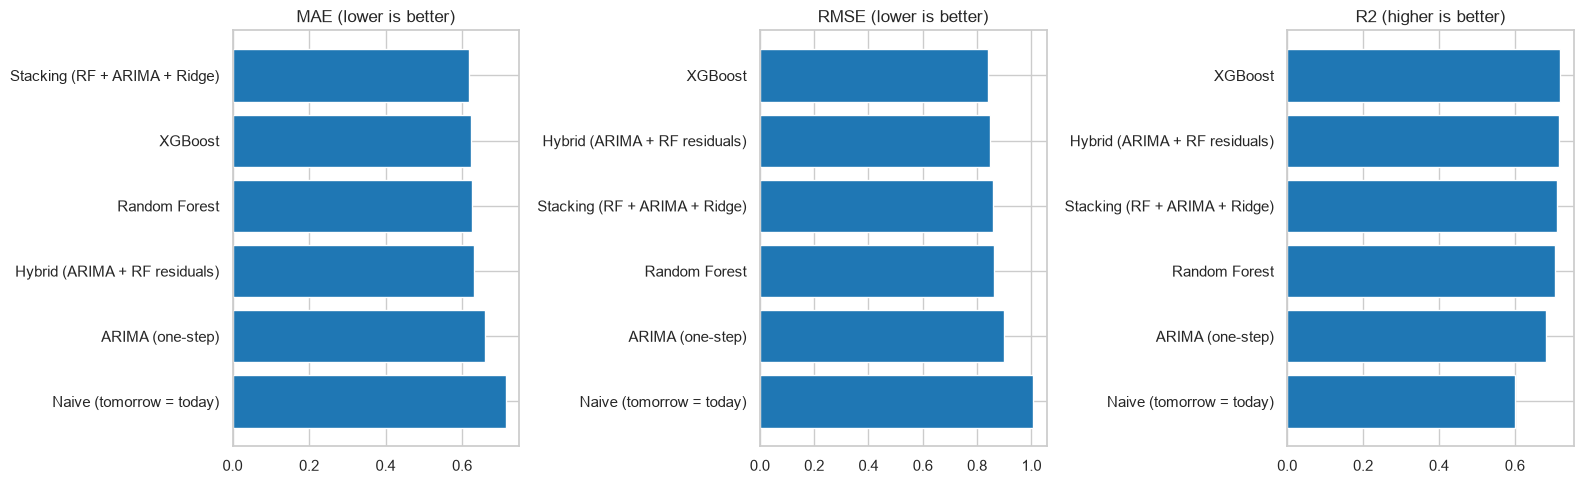

In [44]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric in zip(axes, ["MAE", "RMSE", "R2"]):
    ascending = metric != "R2"  # lower is better for MAE and RMSE
    data = final_results.sort_values(metric, ascending=ascending)
    ax.barh(data["model"], data[metric], color="tab:blue")
    ax.set_title(f"{metric} ({'lower' if ascending else 'higher'} is better)")
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

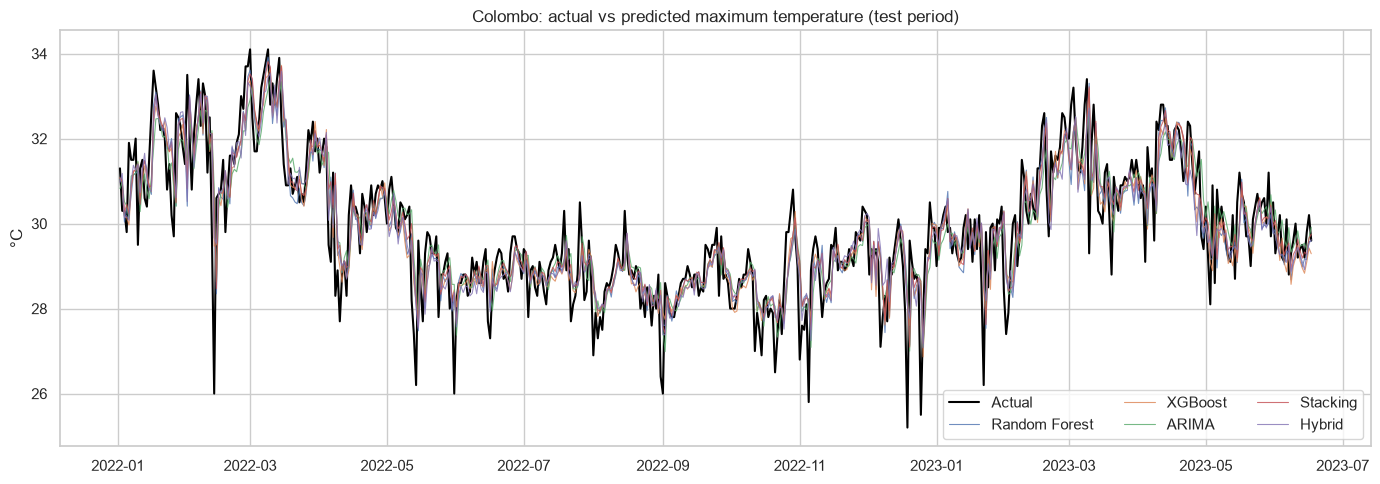

In [45]:
model_cols = ["Random Forest", "XGBoost", "ARIMA", "Stacking", "Hybrid"]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(preds["target_date"], preds["actual"], color="black", lw=1.5, label="Actual")
for col in model_cols:
    ax.plot(preds["target_date"], preds[col], lw=0.8, alpha=0.8, label=col)
ax.set_title("Colombo: actual vs predicted maximum temperature (test period)")
ax.set_ylabel("°C")
ax.legend(ncol=3)
plt.tight_layout()
plt.show()

In [46]:
errors = preds[model_cols].sub(preds["actual"], axis=0)
monthly_rmse = (errors ** 2).groupby(preds["target_date"].dt.month).mean().pow(0.5).round(3)
monthly_rmse

,Random Forest,XGBoost,ARIMA,Stacking,Hybrid
target_date,,,,,
1,0.951,0.922,0.939,0.939,0.922
2,1.164,1.058,1.192,1.152,1.125
3,0.914,0.891,0.876,0.877,0.861
4,0.839,0.863,0.928,0.843,0.872
5,0.898,0.886,0.962,0.897,0.876
6,0.489,0.559,0.530,0.471,0.525
7,0.619,0.636,0.696,0.635,0.600
8,0.641,0.622,0.727,0.667,0.647
9,0.534,0.555,0.590,0.545,0.540


### Findings
- **Overall ranking (by RMSE):** XGBoost 0.842, Hybrid 0.848, Stacking 0.857, Random Forest 0.862, ARIMA 0.898, Naive 1.006. The four ensemble models are within 0.02 °C of each other, so the differences are small.
- **Monthly pattern:** errors are largest in February (about 1.06 to 1.19) and December (about 1.13 to 1.20), and smallest in June and September (about 0.47 to 0.59). Months 7 to 12 include only 2022, so their figures are less reliable.
- **Model ranking by month:** no single model dominates. XGBoost leads in February, August, October and November, the hybrid in March, May, July and December, Random Forest in April and September, and stacking in June.
- **Actual vs predicted:** all models follow the seasonal level and most day-to-day changes. They all miss sharp one-day drops, which are probably rainy days. Precipitation is not known in advance in this setup, so the models cannot anticipate these drops. This is a hypothesis to check against the precipitation data.

## Interpretation of results
- **Why the models performed as they did:** today's maximum temperature is the strongest predictor, which is why all models outperform the naive baseline by about 14 to 16% in RMSE. Tree-based models (Random Forest and XGBoost) capture non-linear relationships with weather variables, and the hybrid improves ARIMA by modelling its residuals, which contain the patterns ARIMA misses.
- **Why the differences are small:** the ensemble models share the same main information source (recent temperatures) and the same test period. The remaining error comes mostly from rainy-day drops, which none of the models can anticipate from the features used.
- **Strengths and limitations:** XGBoost is the most accurate on RMSE but has the most hyperparameters to tune. The hybrid is more interpretable because ARIMA's contribution is separate, but it needs a time-series setup and its live prediction requires recent history. Stacking gives the best MAE but depends on out-of-fold predictions, which are based on smaller training sets.
- **Research reflection (tabular vs image/text):** tabular weather data with clear features suits tree ensembles well. Image or text data would usually call for deep learning, since the useful features are not manually defined.

In [49]:
import os, json, joblib

os.makedirs("models", exist_ok=True)

joblib.dump(rf_best, "models/random_forest.pkl")
joblib.dump(xgb_best, "models/xgboost.pkl")
joblib.dump(meta, "models/stacking_meta_ridge.pkl")
joblib.dump(resid_model, "models/hybrid_residual_rf.pkl")

with open("models/feature_list.json", "w") as f:
    json.dump(FEATURES, f)

# ARIMA is saved as its order and parameters, then refitted in the dashboard
with open("models/arima_config.json", "w") as f:
    json.dump({"order": list(best_order), "params": [float(x) for x in res_full.params]}, f)

final_results.to_csv("results.csv", index=False)
preds.to_csv("test_predictions.csv", index=False)
print("Saved models, feature list, ARIMA config, results.csv and test_predictions.csv")

Saved models, feature list, ARIMA config, results.csv and test_predictions.csv


## AI Usage Acknowledgment

I used a generative AI assistant to help with:

All modelling decisions, results and interpretations were reviewed and verified by me.